### Importera verktyg, läsa in fil, konvertera till CSV

In [4]:
#importerar in verktyg och bibliotek
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


#läser in vår fil
df_flanker = pd.read_excel("Raw_Flanker.xlsx")

#spara som csv i samma directory
df_flanker.to_csv("Raw_Flanker.csv", index=False)

### Utforska och få en överblick över datan
Titta efter NaN, se vilka kolumner vi behöver och hur vi på andra sätt kan förenkla vår data till vårt syfte

In [6]:
#utforska datan

df_flanker = pd.read_csv("Raw_Flanker.csv")

print("Flanker info")
df_flanker.info()
display(df_flanker.head())


Flanker info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123084 entries, 0 to 123083
Data columns (total 18 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   build                 123084 non-null  object
 1   computer.platform     123084 non-null  object
 2   date                  123084 non-null  int64 
 3   time                  123084 non-null  object
 4   values.practice       123084 non-null  int64 
 5   blockcode             123084 non-null  object
 6   blocknum              123084 non-null  int64 
 7   values.blockcount     123084 non-null  int64 
 8   trialcode             123084 non-null  object
 9   trialnum              123084 non-null  int64 
 10  values.trialcount     123084 non-null  int64 
 11  values.congruence     123084 non-null  int64 
 12  values.selecttarget   123084 non-null  int64 
 13  values.selectflanker  123084 non-null  int64 
 14  response              123084 non-null  int64 
 15  corr

,build,computer.platform,date,time,values.practice,blockcode,blocknum,values.blockcount,trialcode,trialnum,values.trialcount,values.congruence,values.selecttarget,values.selectflanker,response,correct,latency,subjectid
0,5.0.6.0,win,111917,11:21:10,1,practice,2,0,targetleft_congruent,2,1,1,2,2,16,1,867,1
1,5.0.6.0,win,111917,11:21:10,1,practice,2,0,targetright_congruent,4,2,1,1,1,25,1,416,1
2,5.0.6.0,win,111917,11:21:10,1,practice,2,0,targetright_incongruent,6,3,2,1,2,25,1,391,1
3,5.0.6.0,win,111917,11:21:10,1,practice,2,0,targetright_incongruent,8,4,2,1,2,25,1,467,1
4,5.0.6.0,win,111917,11:21:10,1,practice,2,0,targetright_congruent,10,5,1,1,1,25,1,389,1


In [7]:
#check for NaN

print("Tot NaN for Flanker-test")
df_flanker.isna().sum()



Tot NaN for Flanker-test


build                   0
computer.platform       0
date                    0
time                    0
values.practice         0
blockcode               0
blocknum                0
values.blockcount       0
trialcode               0
trialnum                0
values.trialcount       0
values.congruence       0
values.selecttarget     0
values.selectflanker    0
response                0
correct                 0
latency                 0
subjectid               0
dtype: int64

### Cleana vår data
Välja kolumner som vi vill ha kvar, sortera, skapa ny kolumn 'session', ta bort practiceruns, göra 'date' tydligare etc

In [9]:
# läser in csv filen
df_flanker = pd.read_csv("Raw_Flanker.csv")

In [10]:
# gör datumet mer lättläst
df_flanker['date'] = pd.to_datetime(df_flanker['date'].astype(str).str.zfill(6), format='%m%d%y', errors='coerce').dt.strftime('%Y-%m-%d')

In [11]:
# sortera kronologiskt efter deltagare, datum och tid så sessionerna hamnar i rätt ordning
df_flanker = df_flanker.sort_values(by=['subjectid', 'date', 'time'])

In [12]:
# skapa 'session'-kolumnen per deltagare (1 = tidigaste tillfället, 2 = nästa, 3 = sista)
df_flanker['session'] = df_flanker.groupby('subjectid')['date'].transform(lambda x: pd.factorize(x)[0] + 1)

In [13]:
# ta bort övningsförsök
df_clean = df_flanker[df_flanker['values.practice'] == 0].copy()

In [14]:
# välj enbart de kolumner vi vill behålla (inklusive 'session')
kolumner_att_behålla = ['date', 'time', 'subjectid', 'session', 'correct', 'values.congruence', 'latency']

In [15]:
# kontrollera att kolumnerna finns
df_clean = df_clean[[col for col in kolumner_att_behålla if col in df_clean.columns]]

### Kontrollera våran data
Se över att allt ser korrekt ut och som vi vill ha det, kan vi göra ytterligare förbättringar.

In [17]:
#kontrollera våran data efter vi cleanat den

display(df_clean.head())
df_clean.info()

df_clean['subjectid'].nunique()

antal_unika = df_clean['subjectid'].nunique()
print(f"Antal unika deltagare: {antal_unika}")



,date,time,subjectid,session,correct,values.congruence,latency
11,2017-11-19,11:21:10,1,1,1,2,378
12,2017-11-19,11:21:10,1,1,0,2,379
13,2017-11-19,11:21:10,1,1,1,2,719
14,2017-11-19,11:21:10,1,1,1,2,417
15,2017-11-19,11:21:10,1,1,1,1,438


<class 'pandas.core.frame.DataFrame'>
Index: 114405 entries, 11 to 123083
Data columns (total 7 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   date               114405 non-null  object
 1   time               114405 non-null  object
 2   subjectid          114405 non-null  int64 
 3   session            114405 non-null  int64 
 4   correct            114405 non-null  int64 
 5   values.congruence  114405 non-null  int64 
 6   latency            114405 non-null  int64 
dtypes: int64(5), object(2)
memory usage: 7.0+ MB
Antal unika deltagare: 466


In [43]:
# skapa unika sessions med hjälpa av date och subject id
df_flanker['session'] = df_flanker.groupby('subjectid')['date'].transform(lambda x: pd.factorize(x)[0] + 1)

#kontrollera hur det ser ut för en person med 1 eller flera sessions
print(df_flanker[df_flanker['subjectid'] == 45][['subjectid', 'date', 'time', 'session']].drop_duplicates())

      subjectid        date      time  session
6864         45  2017-11-29  16:47:45        1


In [19]:
# spara ner allt till EN gemensam CSV-fil (ta bort # för att spara ner en ny csv fil med cleanad data)

#df_clean.to_csv("flanker_all_sessions_combined.csv", index=False)

print("Ta bort # ovan för att spara ner en ny 'cleanad' csv, 'flanker_all_sessions_combined.csv'.")

Ta bort # ovan för att spara ner en ny 'cleanad' csv, 'flanker_all_sessions_combined.csv'.


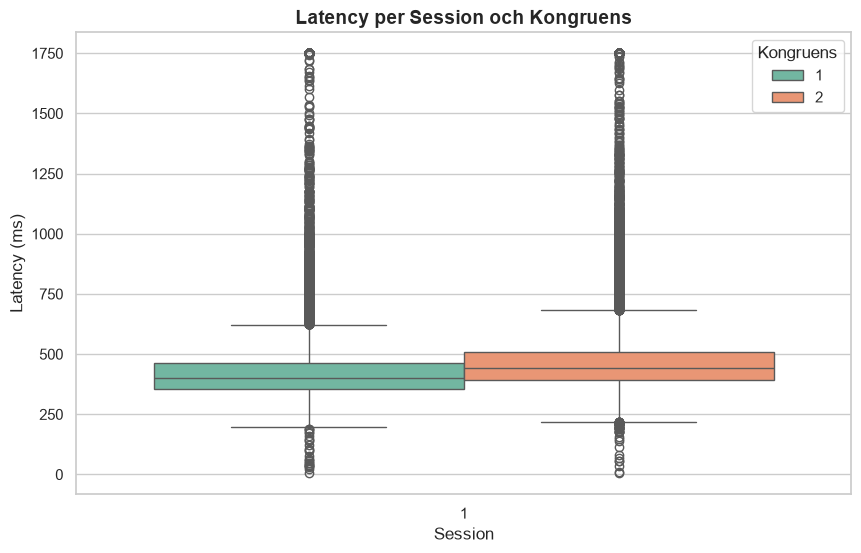

In [45]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    x='session', 
    y='latency', 
    hue='values.congruence', 
    data=df_clean[df_clean['session'] == 1], 
    palette='Set2'
)
plt.title('Latency per Session och Kongruens', fontsize=14, fontweight='bold')
plt.xlabel('Session', fontsize=12)
plt.ylabel('Latency (ms)', fontsize=12)
plt.legend(title='Kongruens')
plt.show()